<a href="https://colab.research.google.com/github/nabillahumi/S5-Mesin_Learning/blob/main/Jobsheet4%20PBL/Praktikum%202%20(JS4)%20PBL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Langkah 1: Import Library dan Pemuatan Dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
from sklearn.cluster import KMeans, MiniBatchKMeans, SpectralClustering
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, confusion_matrix
from scipy.stats import mode

# Membaca dataset cafes.csv dan reviews.csv
df_cafes = pd.read_csv('cafes.csv')
df_reviews = pd.read_csv('reviews.csv')

print("Jumlah data kafe:", df_cafes.shape)
print("Jumlah data review:", df_reviews.shape)

Jumlah data kafe: (99, 12)
Jumlah data review: (2230, 8)


#Langkah 2: Pengantar k-Means (Visualisasi Fitur Kafe)

/tmp/ipykernel_938/878011608.py:5: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(X_cafe[:, 0], X_cafe[:, 1], s=50, cmap='viridis')


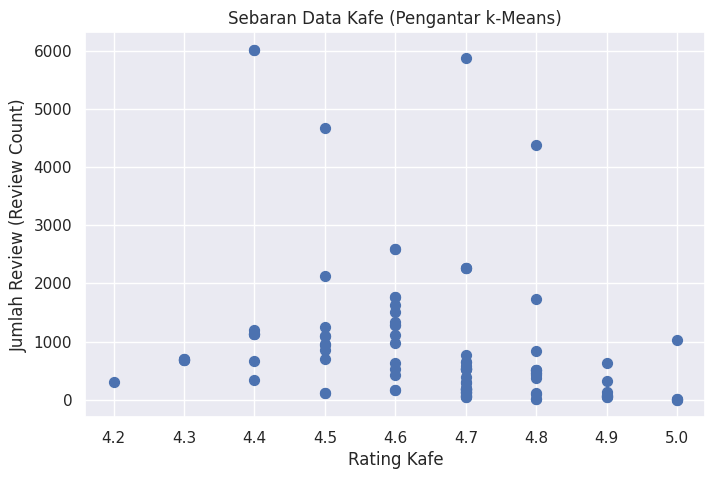

In [3]:
# Menggunakan fitur rating dan review_count dari cafes.csv
X_cafe = df_cafes[['rating', 'review_count']].values

plt.figure(figsize=(8, 5))
plt.scatter(X_cafe[:, 0], X_cafe[:, 1], s=50, cmap='viridis')
plt.xlabel('Rating Kafe')
plt.ylabel('Jumlah Review (Review Count)')
plt.title('Sebaran Data Kafe (Pengantar k-Means)')
plt.show()

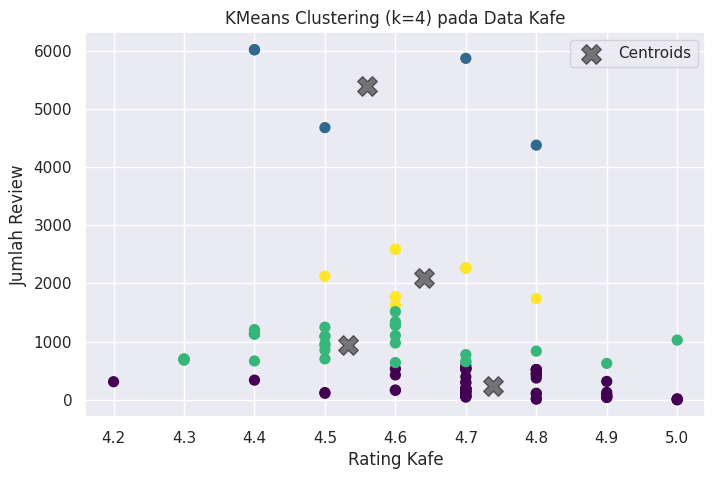

In [4]:
# Terapkan KMeans dengan k=4 pada data kafe
kmeans = KMeans(n_clusters=4, random_state=0, n_init='auto')
kmeans.fit(X_cafe)
y_kmeans = kmeans.predict(X_cafe)

# Plot hasil klaster dan titik pusat (centroid)
plt.figure(figsize=(8, 5))
plt.scatter(X_cafe[:, 0], X_cafe[:, 1], c=y_kmeans, s=50, cmap='viridis')
centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='black', s=200, alpha=0.5, marker='X', label='Centroids')
plt.xlabel('Rating Kafe')
plt.ylabel('Jumlah Review')
plt.title('KMeans Clustering (k=4) pada Data Kafe')
plt.legend()
plt.show()

#Langkah 3: Algoritma Expectation-Maximization (Custom find_clusters)

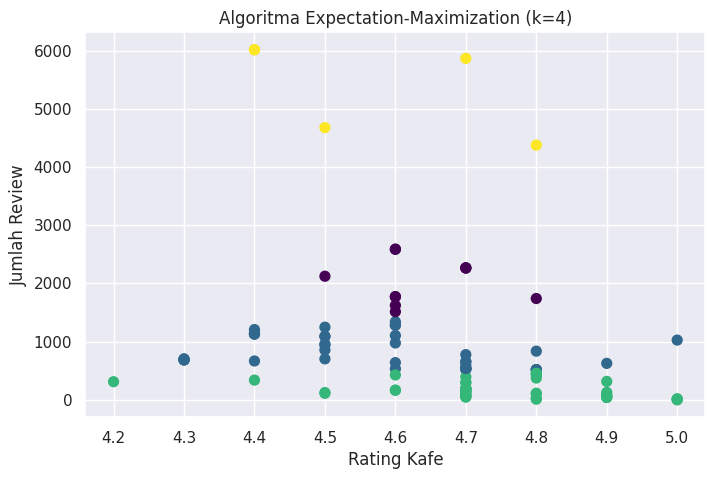

In [5]:
from sklearn.metrics import pairwise_distances_argmin

def find_clusters(X, n_clusters, rseed=2):
    # 1. Randomly choose clusters
    rng = np.random.RandomState(rseed)
    i = rng.permutation(X.shape[0])[:n_clusters]
    centers = X[i]

    while True:
        # 2a. Input label center yang baru
        labels = pairwise_distances_argmin(X, centers)

        # 2b. Update center dari titik baru
        new_centers = np.array([X[labels == i].mean(0)
                                for i in range(n_clusters)])

        # 2c. Cek konvergensi
        if np.all(centers == new_centers):
            break
        centers = new_centers

    return centers, labels

# Menjalankan fungsi find_clusters dengan 4 klaster
centers, labels = find_clusters(X_cafe, 4)

plt.figure(figsize=(8, 5))
plt.scatter(X_cafe[:, 0], X_cafe[:, 1], c=labels, s=50, cmap='viridis')
plt.xlabel('Rating Kafe')
plt.ylabel('Jumlah Review')
plt.title('Algoritma Expectation-Maximization (k=4)')
plt.show()

#Langkah 4: Perubahan Random (rseed=0)

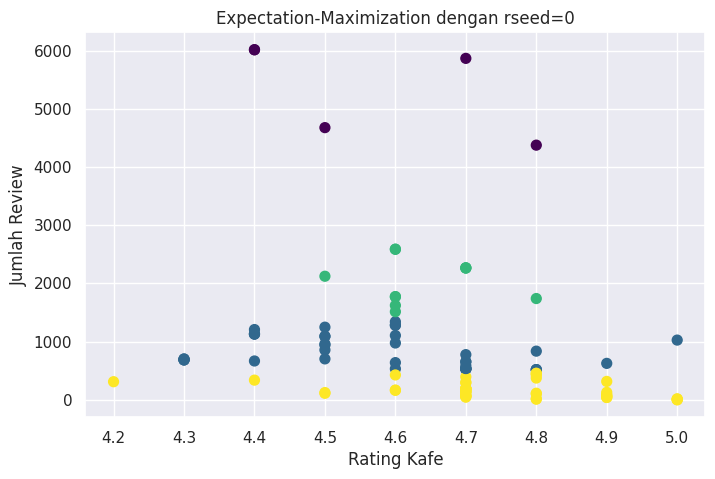

In [6]:
centers, labels = find_clusters(X_cafe, 4, rseed=0)

plt.figure(figsize=(8, 5))
plt.scatter(X_cafe[:, 0], X_cafe[:, 1], c=labels, s=50, cmap='viridis')
plt.xlabel('Rating Kafe')
plt.ylabel('Jumlah Review')
plt.title('Expectation-Maximization dengan rseed=0')
plt.show()

#Langkah 5: Optimalisasi Jumlah Klaster ($k=6$)

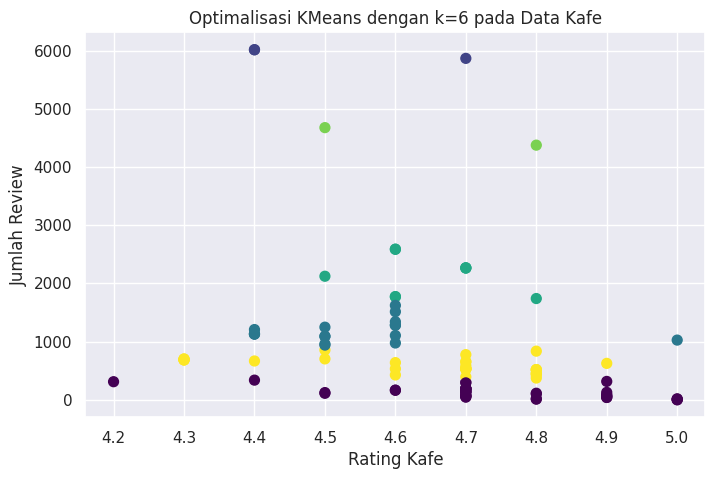

In [7]:
labels_k6 = KMeans(n_clusters=6, random_state=0, n_init='auto').fit_predict(X_cafe)

plt.figure(figsize=(8, 5))
plt.scatter(X_cafe[:, 0], X_cafe[:, 1], c=labels_k6, s=50, cmap='viridis')
plt.xlabel('Rating Kafe')
plt.ylabel('Jumlah Review')
plt.title('Optimalisasi KMeans dengan k=6 pada Data Kafe')
plt.show()

#Langkah 6: Batas Klaster yang Tidak Selalu Linier (SpectralClustering)

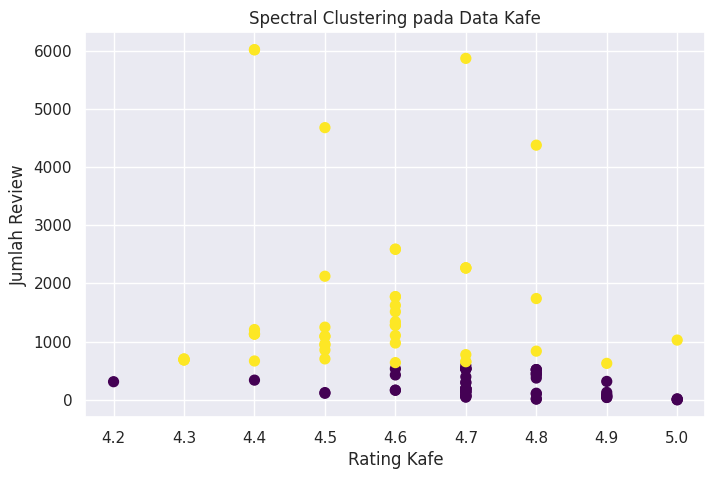

In [8]:
model = SpectralClustering(n_clusters=2, affinity='nearest_neighbors', assign_labels='kmeans', random_state=0)
labels_spec = model.fit_predict(X_cafe)

plt.figure(figsize=(8, 5))
plt.scatter(X_cafe[:, 0], X_cafe[:, 1], c=labels_spec, s=50, cmap='viridis')
plt.xlabel('Rating Kafe')
plt.ylabel('Jumlah Review')
plt.title('Spectral Clustering pada Data Kafe')
plt.show()

#Langkah 7: Contoh Kasus — Analisis & Klasterisasi Teks Ulasan (reviews.csv)

Bentuk data teks ulasan: (2230,)
Bentuk matriks TF-IDF: (2230, 100)
Akurasi Klaster Teks Ulasan: 0.8058


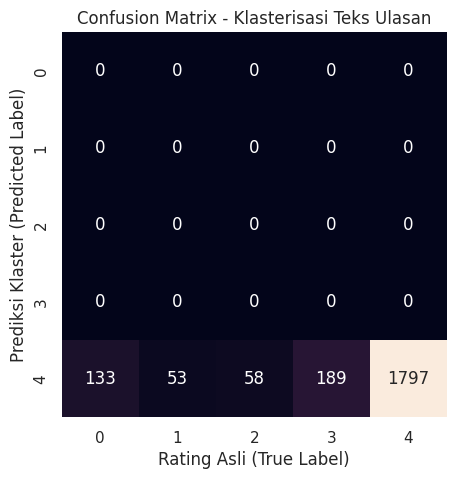

In [9]:
# 1. Menyiapkan teks ulasan dari reviews.csv
text_data = df_reviews['text'].fillna('').values
true_ratings = df_reviews['rating'].astype(int).values

print("Bentuk data teks ulasan:", text_data.shape)

# 2. Ekstraksi fitur teks menggunakan TF-IDF
vectorizer = TfidfVectorizer(max_features=100, stop_words='english')
X_text = vectorizer.fit_transform(text_data).toarray()
print("Bentuk matriks TF-IDF:", X_text.shape)

# 3. Menerapkan KMeans (misal k=5 klaster sesuai skala rating 1-5)
kmeans_text = KMeans(n_clusters=5, random_state=0, n_init='auto')
clusters_text = kmeans_text.fit_predict(X_text)

# 4. Pencocokan label klaster dengan true rating menggunakan SciPy mode
labels_mapped = np.zeros_like(clusters_text)
for i in range(5):
    mask = (clusters_text == i)
    if np.any(mask):
        labels_mapped[mask] = mode(true_ratings[mask], keepdims=True)[0][0]

# Hitung akurasi klaster terhadap rating asli
acc = accuracy_score(true_ratings, labels_mapped)
print(f"Akurasi Klaster Teks Ulasan: {acc:.4f}")

# 5. Confusion Matrix
plt.figure(figsize=(6, 5))
mat = confusion_matrix(true_ratings, labels_mapped)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False)
plt.xlabel('Rating Asli (True Label)')
plt.ylabel('Prediksi Klaster (Predicted Label)')
plt.title('Confusion Matrix - Klasterisasi Teks Ulasan')
plt.show()

In [10]:
# Reduksi dimensi dengan t-SNE
tsne = TSNE(n_components=2, init='random', random_state=0, perplexity=30)
text_proj = tsne.fit_transform(X_text)

# Klasterisasi ulang pada data proyeksi t-SNE
kmeans_tsne = KMeans(n_clusters=5, random_state=0, n_init='auto')
clusters_tsne = kmeans_tsne.fit_predict(text_proj)

labels_tsne_mapped = np.zeros_like(clusters_tsne)
for i in range(5):
    mask = (clusters_tsne == i)
    if np.any(mask):
        labels_tsne_mapped[mask] = mode(true_ratings[mask], keepdims=True)[0][0]

acc_tsne = accuracy_score(true_ratings, labels_tsne_mapped)
print(f"Akurasi t-SNE Text Clustering: {acc_tsne:.4f}")

Akurasi t-SNE Text Clustering: 0.8058


#Langkah 8: Studi Kasus — MiniBatchKMeans pada Data Kafe

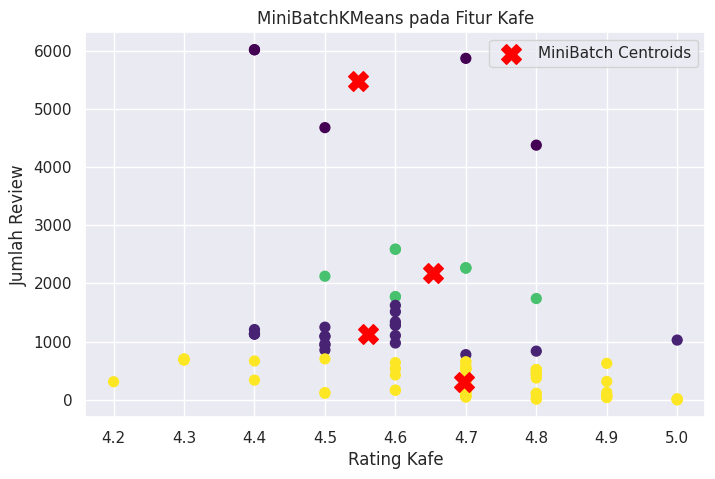

In [11]:
# Menerapkan MiniBatchKMeans pada fitur kafe
minibatch_kmeans = MiniBatchKMeans(n_clusters=4, random_state=0, n_init='auto')
minibatch_kmeans.fit(X_cafe)
new_cafe_features = minibatch_kmeans.cluster_centers_[minibatch_kmeans.predict(X_cafe)]

# Plot hasil kuantisasi/pengelompokan fitur kafe
plt.figure(figsize=(8, 5))
plt.scatter(X_cafe[:, 0], X_cafe[:, 1], c=new_cafe_features[:, 0], s=50, cmap='viridis')
centers_mb = minibatch_kmeans.cluster_centers_
plt.scatter(centers_mb[:, 0], centers_mb[:, 1], c='red', s=200, marker='X', label='MiniBatch Centroids')
plt.xlabel('Rating Kafe')
plt.ylabel('Jumlah Review')
plt.title('MiniBatchKMeans pada Fitur Kafe')
plt.legend()
plt.show()